A partir de este notebook:

1. Analiza todas las variables.
2. Calcula Pearson y Spearman.
3. Busca diferencias importantes entre ambos coeficientes.
4. Identifica posibles relaciones no lineales.
5. Analiza las variables categóricas.
6. Aplica One-Hot Encoding.
7. Prueba una transformación logarítmica sobre otra variable.
8. Compara StandardScaler y MinMaxScaler.
9. Calcula información mutua.
10. Propón un conjunto final de variables de entrada.
11. Justifica las variables descartadas.
12. Redacta un pequeño informe técnico.
13. Mostrar todos los histogramas de las variables, incluyendo su función de densidad.
14. Comentario de cada histograma analizando, tipo de distribución, sesgo, posible presencia de outliers.
15. Generar Box-plots de todas las variables.
16. Comentario de cada Box-plot, analizando cuartiles y posible presencia de outliers.
17. Análisis de todas las variables dos a dos, usando Información Mutua.
18. Comentario de los valores obtenidos.
19. Realizar tabla de contingencia y V de Cramér.
20. Comentario de los valores obtenidos.
21. Calcular VIF (Variance Inflation Factor) para comprobar Multicolinealidad.
22. Comentario de los valores obtenidos.
23. Una vez analizadas todas las relaciones entre datos, realizar una propuesta previa de variables a usar y descartar para entrenar el  modelo, justificando cada caso.


### Pregunta final

> ¿Qué variables utilizarías para construir un primer modelo de predicción del precio y por qué?


In [1]:
# Importar librerías

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.feature_selection import mutual_info_regression

plt.rcParams["figure.figsize"] = (8, 5)
sns.set_style("whitegrid")


In [2]:
# Cargar el conjunto de datos

df = pd.read_csv("viviendas.csv")

df.head()


,id_vivienda,superficie,habitaciones,antiguedad,municipio,ascensor,planta,precio
0,1001,156,3,10,Granada,Sí,4,395000
1,1002,97,2,22,Málaga,Sí,2,302000
2,1003,72,1,22,Granada,Sí,3,205000
3,1004,111,3,30,Córdoba,Sí,4,329000
4,1005,112,2,40,Sevilla,Sí,6,200000


# 1. Analiza todas las variables.


In [3]:
print("Filas y columnas:", df.shape)
print("\nTipos de datos e información general:")
df.info()


Filas y columnas: (120, 8)

Tipos de datos e información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   id_vivienda   120 non-null    int64 
 1   superficie    120 non-null    int64 
 2   habitaciones  120 non-null    int64 
 3   antiguedad    120 non-null    int64 
 4   municipio     120 non-null    object
 5   ascensor      120 non-null    object
 6   planta        120 non-null    int64 
 7   precio        120 non-null    int64 
dtypes: int64(6), object(2)
memory usage: 7.6+ KB


In [4]:
# Estadísticas descriptivas de las variables numéricas
df.describe()


,id_vivienda,superficie,habitaciones,antiguedad,planta,precio
count,120.000000,120.000000,120.000000,120.000000,120.000000,120.000000
mean,1060.500000,105.700000,2.816667,23.825000,3.200000,300875.000000
std,34.785054,33.410259,1.076747,14.901166,2.124685,83856.576487
min,1001.000000,45.000000,1.000000,0.000000,0.000000,154000.000000
25%,1030.750000,81.250000,2.000000,12.750000,2.000000,242500.000000
50%,1060.500000,100.500000,3.000000,24.000000,3.000000,281000.000000
75%,1090.250000,125.250000,3.000000,33.250000,5.000000,354250.000000
max,1120.000000,210.000000,5.000000,61.000000,8.000000,650000.000000


In [5]:
# Resumen de las variables categóricas
df.describe(include="object")


,municipio,ascensor
count,120,120
unique,5,2
top,Málaga,Sí
freq,32,101


In [6]:
# Comprobación de valores nulos
df.isna().sum()


id_vivienda     0
superficie      0
habitaciones    0
antiguedad      0
municipio       0
ascensor        0
planta          0
precio          0
dtype: int64

- 120 viviendas, 8 columnas, sin valores nulos.
- `id_vivienda` se descarta: es solo un identificador.
- Numéricas con rangos normales; `precio` entre 154.000 € y 650.000 € (media ≈300.875 €).
- Categóricas: `municipio` (5 ciudades) y `ascensor` (Sí/No).


## 2. Calcula Pearson y Spearman.


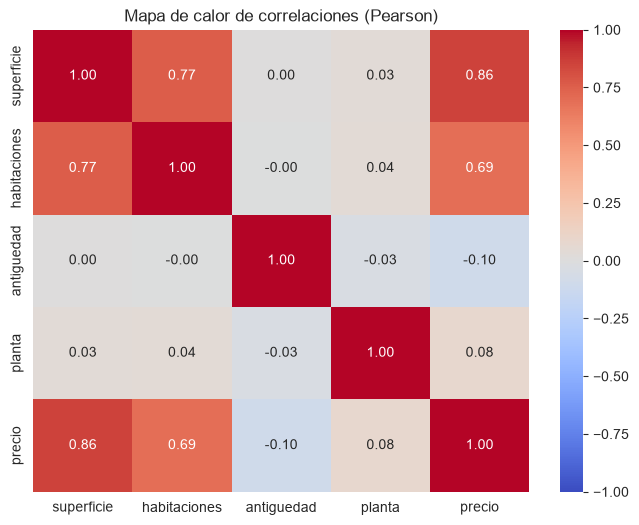

In [7]:
# Pearson

# Calculamos la matriz de correlación para las variables numéricas de interés
variables_numericas = ["superficie", "habitaciones", "antiguedad", "planta", "precio"]
matriz_corr = df[variables_numericas].corr()

# Dibujamos el mapa de calor
plt.figure(figsize=(8, 6))
sns.heatmap(matriz_corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Mapa de calor de correlaciones (Pearson)")
plt.show()


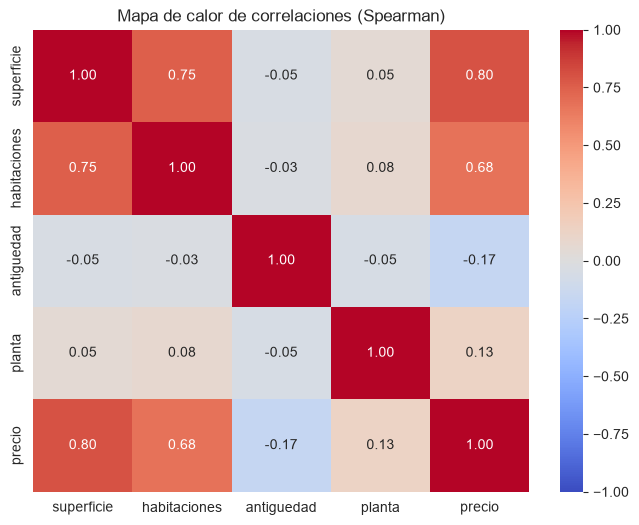

In [8]:
# Spearman
matriz_corr_spearman = df[variables_numericas].corr(method="spearman")

plt.figure(figsize=(8, 6))
sns.heatmap(matriz_corr_spearman, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Mapa de calor de correlaciones (Spearman)")
plt.show()


## 3. Busca diferencias importantes entre ambos coeficientes.


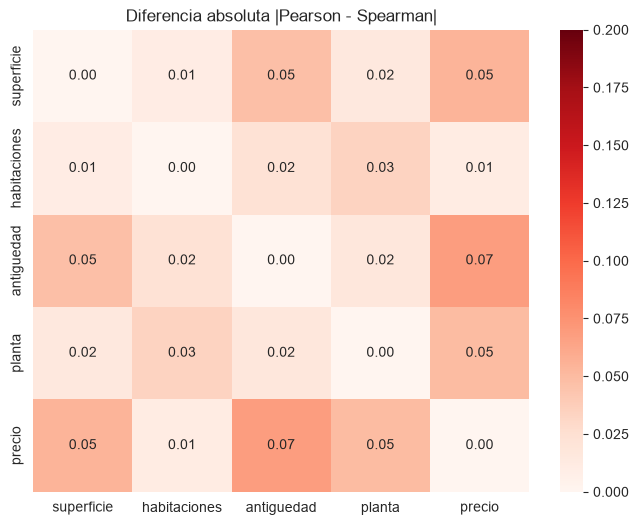

In [9]:
# Diferencia absoluta entre Pearson y Spearman para cada par de variables
diferencia = (matriz_corr - matriz_corr_spearman).abs()

plt.figure(figsize=(8, 6))
sns.heatmap(diferencia, annot=True, cmap="Reds", fmt=".2f", vmin=0, vmax=0.2)
plt.title("Diferencia absoluta |Pearson - Spearman|")
plt.show()


Mayor diferencia en `antiguedad`-`precio` (≈0.07): relación débil y no del todo lineal. En `superficie` y `habitaciones` ambos coeficientes coinciden (relación fuerte y lineal).


## 4. Identifica posibles relaciones no lineales.


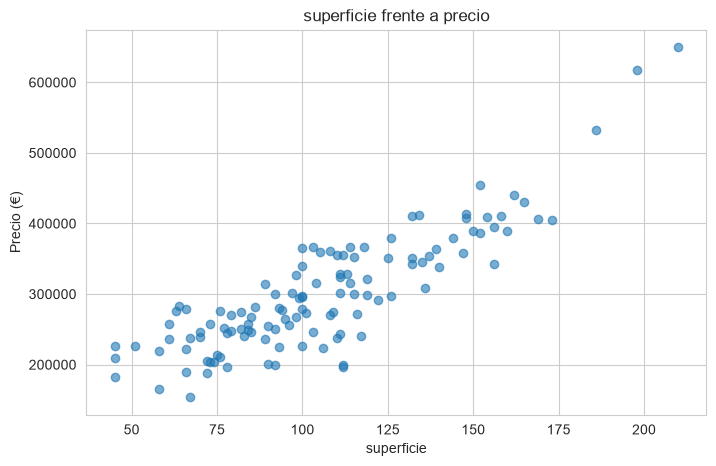

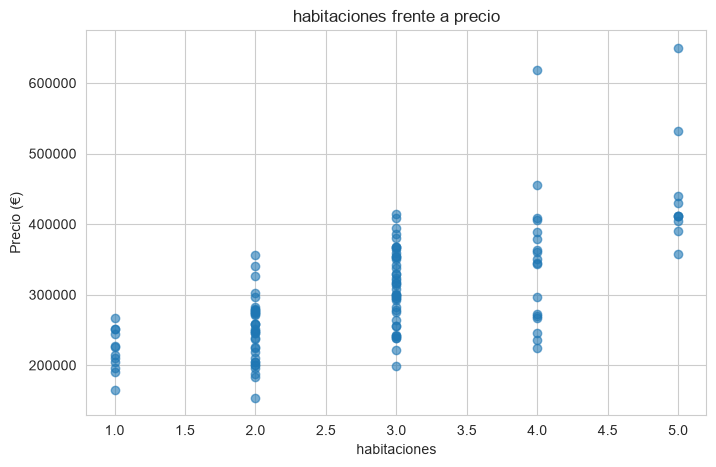

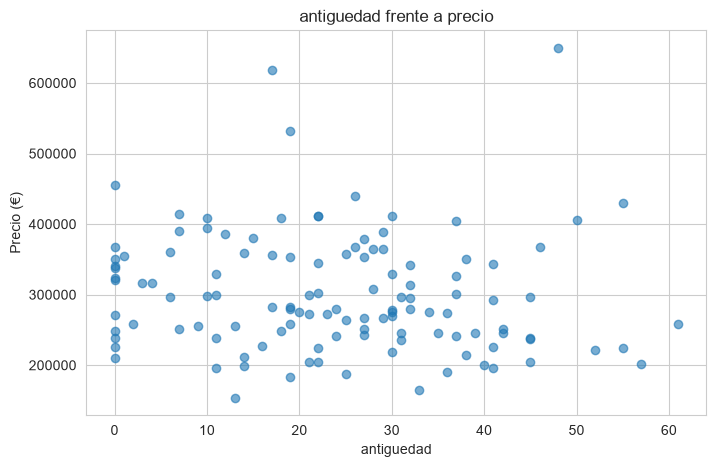

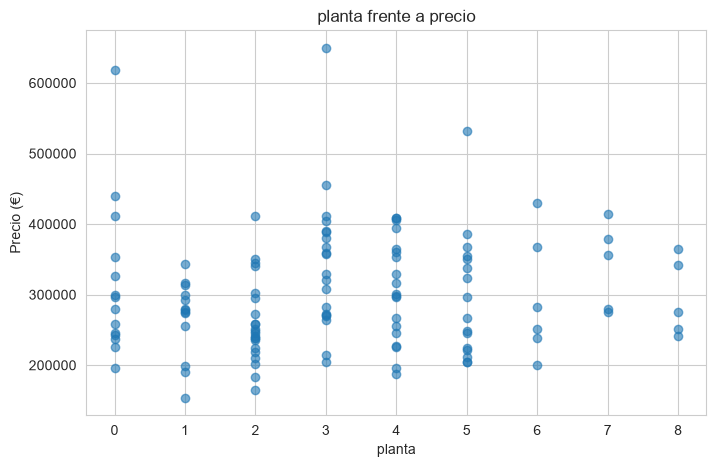

In [10]:
variables = ["superficie", "habitaciones", "antiguedad", "planta"]

for variable in variables:
    plt.scatter(df[variable], df["precio"], alpha=0.6)
    plt.xlabel(variable)
    plt.ylabel("Precio (€)")
    plt.title(f"{variable} frente a precio")
    plt.show()


`superficie` y `habitaciones` muestran relación lineal clara. `antiguedad` y `planta` no muestran ningún patrón.


## 5. Analiza las variables categóricas.


In [11]:
variables_categoricas = df.select_dtypes(exclude="number").columns.tolist()
print("Variables categóricas:", variables_categoricas)


Variables categóricas: ['municipio', 'ascensor']


In [12]:
for col in variables_categoricas:
    print(f"\n--- {col} ---")
    print(df[col].value_counts())
    print("\nPrecio medio por categoría:")
    print(df.groupby(col)["precio"].mean().round(0))



--- municipio ---
municipio
Málaga     32
Sevilla    31
Granada    24
Córdoba    24
Cádiz       9
Name: count, dtype: int64

Precio medio por categoría:
municipio
Cádiz      342889.0
Córdoba    283083.0
Granada    299625.0
Málaga     312125.0
Sevilla    291806.0
Name: precio, dtype: float64

--- ascensor ---
ascensor
Sí    101
No     19
Name: count, dtype: int64

Precio medio por categoría:
ascensor
No    291632.0
Sí    302614.0
Name: precio, dtype: float64


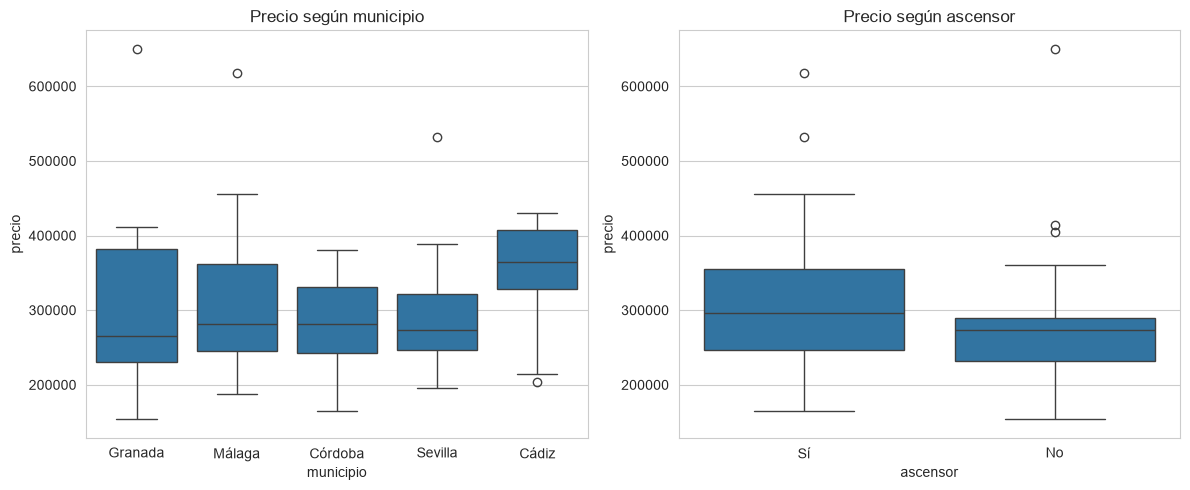

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, col in zip(axes, variables_categoricas):
    sns.boxplot(data=df, x=col, y="precio", ax=ax)
    ax.set_title(f"Precio según {col}")

plt.tight_layout()
plt.show()


`municipio`: el precio medio varía entre ≈283.000 € (Córdoba) y ≈343.000 € (Cádiz). `ascensor`: diferencia pequeña (≈303.000 € vs ≈292.000 €), poco relevante.


## 6. Aplica One-Hot Encoding.


One-Hot Encoding convierte una variable categórica en columnas binarias, evitando imponer un orden artificial. `municipio` lo necesita; `ascensor`, al ser binaria, solo se mapea a 0/1.


In [14]:
df_encoded = pd.get_dummies(
    df,
    columns=["municipio"],
    dtype=int
)

df_encoded["ascensor"] = df_encoded["ascensor"].map({"Sí": 1, "No": 0})

df_encoded.head()


,id_vivienda,superficie,habitaciones,antiguedad,ascensor,planta,precio,municipio_Cádiz,municipio_Córdoba,municipio_Granada,municipio_Málaga,municipio_Sevilla
0,1001,156,3,10,1,4,395000,0,0,1,0,0
1,1002,97,2,22,1,2,302000,0,0,0,1,0
2,1003,72,1,22,1,3,205000,0,0,1,0,0
3,1004,111,3,30,1,4,329000,0,1,0,0,0
4,1005,112,2,40,1,6,200000,0,0,0,0,1


## 7. Prueba una transformación logarítmica sobre otra variable.


Aplicamos `log1p` a `superficie`, la variable con más sesgo.


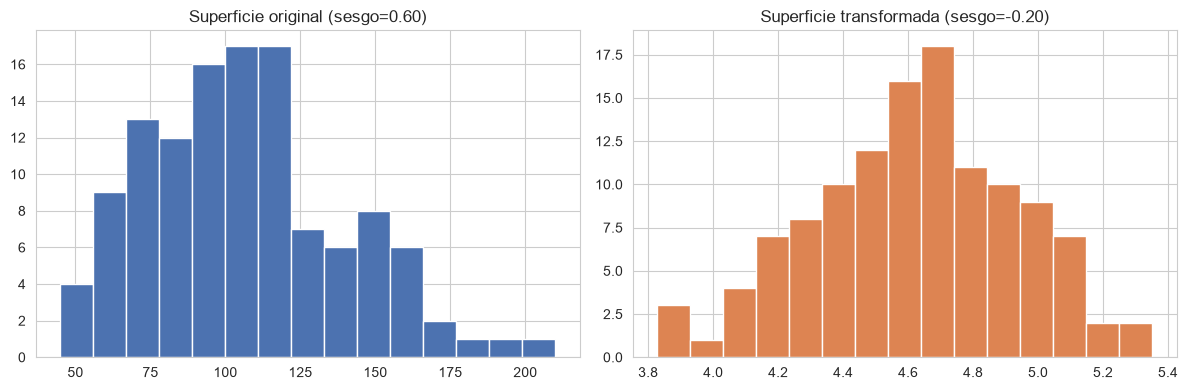

,superficie,superficie_log
0,156,5.056246
1,97,4.584967
2,72,4.290459
3,111,4.718499
4,112,4.727388


In [15]:
df["superficie_log"] = np.log1p(df["superficie"])

sesgo_antes = df["superficie"].skew()
sesgo_despues = df["superficie_log"].skew()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df["superficie"], bins=15, color="#4C72B0", edgecolor="white")
axes[0].set_title(f"Superficie original (sesgo={sesgo_antes:.2f})")

axes[1].hist(df["superficie_log"], bins=15, color="#DD8452", edgecolor="white")
axes[1].set_title(f"Superficie transformada (sesgo={sesgo_despues:.2f})")

plt.tight_layout()
plt.show()

df[["superficie", "superficie_log"]].head()


El sesgo baja de 0.60 a -0.20: la distribución queda mucho más simétrica.


## 8. Compara StandardScaler y MinMaxScaler.


**StandardScaler**: media 0, desviación 1, sin rango fijo. Poco sensible a outliers.


In [16]:
variables_escalado = [
    "superficie",
    "habitaciones",
    "antiguedad",
    "planta"
]

scaler = StandardScaler()

X_scaled = scaler.fit_transform(df[variables_escalado])

df_scaled = pd.DataFrame(X_scaled, columns=variables_escalado)

df_scaled.head()


,superficie,habitaciones,antiguedad,planta
0,1.511838,0.170980,-0.931670,0.378105
1,-0.261491,-0.761638,-0.122987,-0.567158
2,-1.012901,-1.694255,-0.122987,-0.094526
3,0.159299,0.170980,0.416135,0.378105
4,0.189355,-0.761638,1.090037,1.323368


**MinMaxScaler**: reajusta todo al rango [0, 1]. Muy sensible a outliers.


In [17]:
minmax = MinMaxScaler()

X_minmax = minmax.fit_transform(df[variables_escalado])

df_minmax = pd.DataFrame(X_minmax, columns=variables_escalado)

df_minmax.head()


,superficie,habitaciones,antiguedad,planta
0,0.672727,0.50,0.163934,0.500
1,0.315152,0.25,0.360656,0.250
2,0.163636,0.00,0.360656,0.375
3,0.400000,0.50,0.491803,0.500
4,0.406061,0.25,0.655738,0.750


In [18]:
# Comparación directa de ambos escalados
comparacion = pd.concat(
    [df_scaled.add_suffix("_std"), df_minmax.add_suffix("_minmax")],
    axis=1
)

comparacion.describe().loc[["min", "max", "mean", "std"]]


,superficie_std,habitaciones_std,antiguedad_std,planta_std,superficie_minmax,habitaciones_minmax,antiguedad_minmax,planta_minmax
min,-1.824425e+00,-1.694255e+00,-1.605572e+00,-1.512421e+00,0.000000,0.000000,0.000000,0.000000
max,3.134885e+00,2.036215e+00,2.505232e+00,2.268631e+00,1.000000,1.000000,1.000000,1.000000
mean,-6.661338e-17,-1.406282e-16,1.480297e-17,-7.401487e-17,0.367879,0.454167,0.390574,0.400000
std,1.004193e+00,1.004193e+00,1.004193e+00,1.004193e+00,0.202486,0.269187,0.244281,0.265586


No hay outliers extremos, así que ambos sirven. `StandardScaler` es más robusto por defecto.


## 9. Calcula información mutua.


Detecta dependencias no necesariamente lineales.
En este caso la variable objetivo es numérica (precio).

In [19]:
X = df[["superficie", "habitaciones", "antiguedad", "planta"]]
y = df["precio"]

mi = mutual_info_regression(X, y, random_state=42)

pd.Series(mi, index=X.columns).sort_values(ascending=False)


superficie      0.622935
habitaciones    0.347299
planta          0.038004
antiguedad      0.002805
dtype: float64

Mismo orden que Pearson/Spearman: `superficie` y `habitaciones` son las más informativas; `planta` y `antiguedad` aportan casi nada.


## 10. Propón un conjunto final de variables de entrada.


**Incluir:** `superficie`, `habitaciones`, `municipio`,`ascensor`.

**Descartar:** `antiguedad` y `planta` (correlación y MI casi nulas), `id_vivienda` (identificador).




## 11. Justifica las variables descartadas.

Como bien indico en el ejercicio 10, las variables que descarto son `antiguedad` y `planta`.

Esto se debe a que las correlaciones que tienen con las demás variables son casi nulas.

## 12. Redacta un pequeño informe técnico.

- El dataset tiene 120 viviendas y 8 variables, sin valores nulos. `id_vivienda` es un identificador y se descarta desde el principio.

- `superficie` y `habitaciones` son las variables más relacionadas con `precio` (Pearson 0.86 y 0.69, MI 0.62 y 0.35), con una relación claramente lineal y sin outliers que la distorsionen demasiado.

- `antigüedad` y `planta` no muestran relación relevante con `precio` en ningún análisis (Pearson, Spearman, MI), así que se descartan como predictoras.

- Las categóricas aportan menos: `municipio` varía algo en precio medio entre ciudades (283.000€-343.000€) y `ascensor` tiene una diferencia pequeña (≈303.000€ vs 292.000€), pero ninguna asociación fuerte con el resto de variables (V de Cramér < 0.3).

- El VIF máximo es 2.42 (entre `superficie` y `habitaciones`), por lo que no hay un problema relevante de multicolinealidad.

- Conclusión: para un primer modelo usaría `superficie`, `habitaciones`, `municipio` y `ascensor`, descartando `antigüedad`, `planta` e `id_vivienda`.


## 13. Mostrar todos los histogramas de las variables, incluyendo su función de densidad.

Mostraremos todas las variables excepto las categoricas.

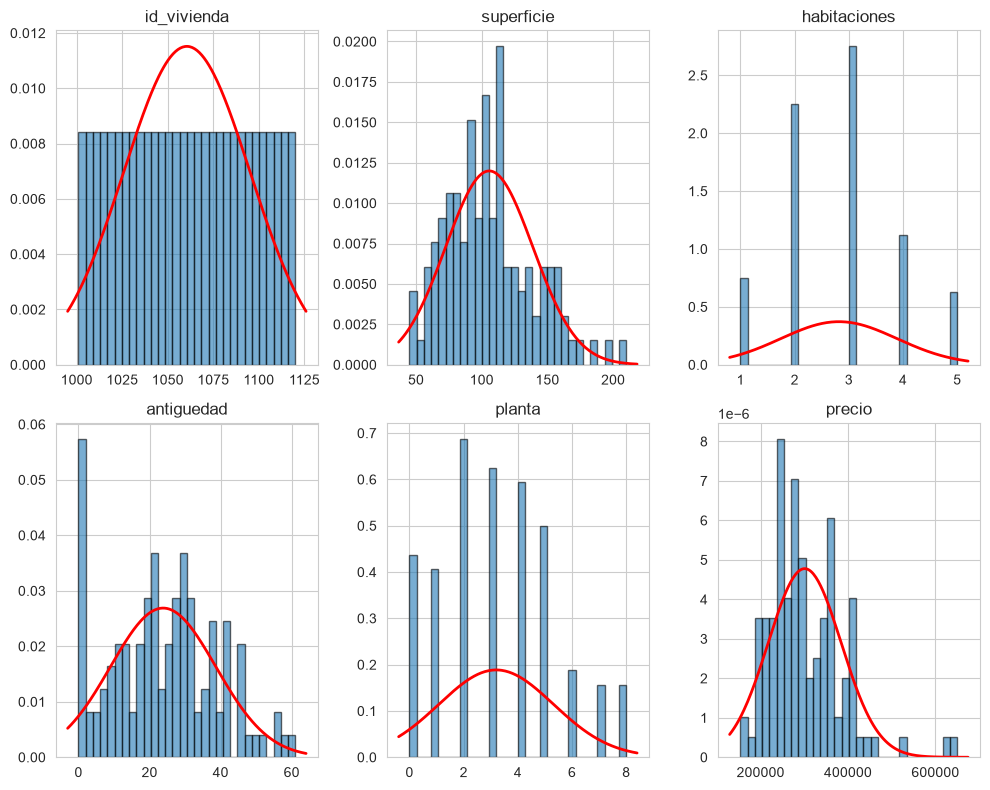

In [20]:
from scipy.stats import norm, skewnorm

# Figura 2×2
fig, axes = plt.subplots(2, 3, figsize=(10, 8))
for ax, col in zip(axes.flatten(), df.drop(['municipio','ascensor'],axis=1)):
    ax.hist(df[col], bins=30, density=True, alpha=0.6, edgecolor="black")
    if col != "OrdinalUniform":               # curva solo para variables continuas
        mu, std = norm.fit(df[col])
        x = np.linspace(ax.get_xlim()[0], ax.get_xlim()[1], 200)
        ax.plot(x, norm.pdf(x, mu, std), "r", linewidth=2)
    ax.set_title(col)
plt.tight_layout()
plt.show()

## 14. Comentario de cada histograma analizando, tipo de distribución, sesgo, posible presencia de outliers.

### Distribución de id_vivienda
Es solo el identificador, va de 1001 a 1120 de forma prácticamente uniforme (sesgo ≈0). No aporta información real y se descarta del análisis, como ya se indicó.

### Distribución de superficie
Sesgo positivo moderado (0.60): cola hacia los valores altos. La mayoría de viviendas está entre 80 y 125 m², y las de 198 y 210 m² estiran la cola derecha sin llegar a ser un problema real.

### Distribución de habitaciones
Variable discreta (1-5) con sesgo ligero (0.29) hacia la derecha. Está concentrada en 2-3 habitaciones; las de 5 habitaciones son pocas y quedan aisladas en la cola.

### Distribución de antigüedad
Sesgo casi nulo (0.16), bastante uniforme entre 0 y 61 años, sin acumulaciones raras ni outliers.

### Distribución de planta
Sesgo bajo (0.38), concentrada entre la planta 2 y 5, sin outliers.

### Distribución de precio
Es la que más sesgo tiene (1.23), con cola larga a la derecha: la mayoría de precios está entre 200.000€ y 350.000€, pero las viviendas por encima de 500.000€ estiran bastante la distribución.


## 15. Generar Box-plots de todas las variables.

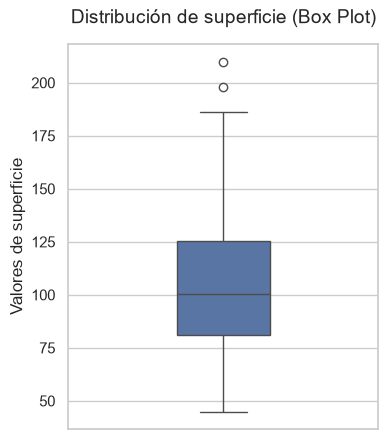

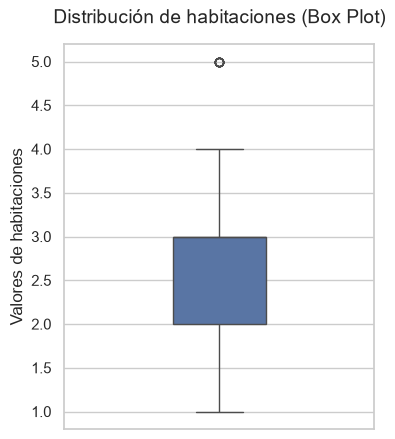

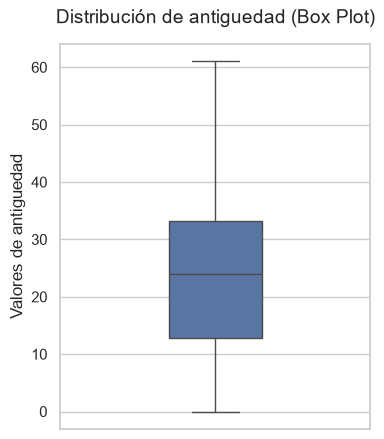

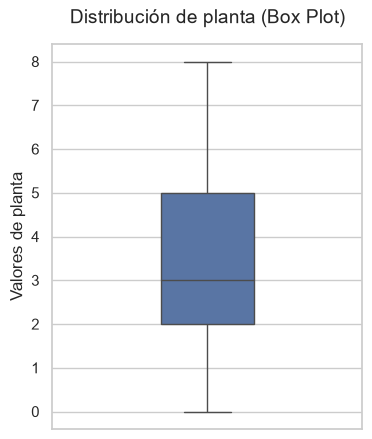

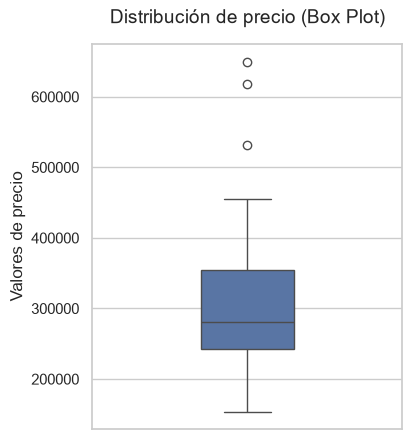

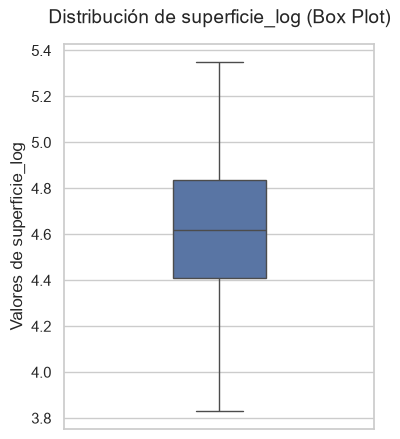

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Configuramos el estilo visual (se hace una sola vez fuera del bucle)
sns.set_theme(style="whitegrid")

# 2. Creamos el bucle for que recorre cada columna del DataFrame
for columna in df.columns.drop(['municipio', 'ascensor','id_vivienda']):  # Excluimos columnas no numéricas

    # Opcional pero recomendado: filtrar para graficar SOLO columnas numéricas
    if df[columna].dtype in ["int64", "float64"]:

        # Seleccionamos los datos de la columna actual
        datos = df[columna]

        # 3. Creamos el gráfico especificando la columna actual
        plt.figure(
            figsize=(4, 5)
        )  # Ajusta el tamaño de la ventana para cada gráfico
        sns.boxplot(y=datos, color="#4c72b0", width=0.3)

        # 4. Añadimos títulos y etiquetas dinámicas usando f-strings
        plt.title(
            f"Distribución de {columna} (Box Plot)", fontsize=14, pad=15
        )
        plt.ylabel(f"Valores de {columna}", fontsize=12)

        # 5. Mostramos el gráfico actual antes de pasar al siguiente en el bucle
        plt.show()



## 16. Comentario de cada Box-plot, analizando cuartiles y posible presencia de outliers.

### Distribución de superficie
IQR entre 81 y 125 m², bastante compacto. Los 2 outliers superiores (198 y 210 m²) son viviendas claramente más grandes que el resto, no parecen errores.


### Distribución de habitaciones
Al ser discreta con pocos valores posibles, el IQR es mínimo (2-3 habitaciones). Las viviendas de 5 habitaciones salen como outlier estadístico por la poca variabilidad, no por ser un dato erróneo.


### Distribución de antigüedad
IQR amplio (13-33 años) y sin outliers: la antigüedad está repartida de forma bastante uniforme, sin viviendas extremadamente nuevas o viejas que destaquen.


### Distribución de planta
IQR entre 2 y 5, sin outliers: las plantas se distribuyen en un rango normal de edificio.


### Distribución de precio
IQR entre 242.500€ y 354.250€. Los 3 outliers superiores (532.000€-650.000€) son viviendas de gama alta, coherentes con las de mayor superficie vistas antes.


### Distribución de superficie_log
IQR estrecho (4.41-4.84) y sin outliers: la transformación logarítmica eliminó los extremos de superficie, dejando una distribución más simétrica.


## 17. Análisis de todas las variables dos a dos, usando Información Mutua.

In [22]:
import pandas as pd
from sklearn.feature_selection import mutual_info_regression

# 1. Metemos TODAS las variables en una sola lista
variables = ["superficie", "habitaciones", "antiguedad", "planta", "precio"]

# 2. El bucle 'for' elige cuál será la variable "objetivo" en cada turno
for objetivo in variables:

    # Las predictores (X) serán todas las demás variables menos la elegida
    otras_variables = [v for v in variables if v != objetivo]

    X = df[otras_variables]
    y = df[objetivo]

    # Calculamos la Información Mutua de todas las demás contra la elegida de golpe
    mi = mutual_info_regression(X, y, random_state=42)

    # Creamos una Serie ordenada de mayor a menor
    ranking = pd.Series(mi, index=X.columns).sort_values(ascending=False)

    # Imprimimos el resultado limpio en pantalla
    print(f"--- Información Mutua contra '{objetivo}' ---")
    print(ranking)
    print("\n" + "-" * 40 + "\n")


--- Información Mutua contra 'superficie' ---
precio          0.619958
habitaciones    0.448767
antiguedad      0.000000
planta          0.000000
dtype: float64

----------------------------------------

--- Información Mutua contra 'habitaciones' ---
superficie    0.448842
precio        0.338279
antiguedad    0.094748
planta        0.043126
dtype: float64

----------------------------------------

--- Información Mutua contra 'antiguedad' ---
habitaciones    0.045737
precio          0.009900
superficie      0.000000
planta          0.000000
dtype: float64

----------------------------------------

--- Información Mutua contra 'planta' ---
habitaciones    0.188070
precio          0.045223
antiguedad      0.000580
superficie      0.000000
dtype: float64

----------------------------------------

--- Información Mutua contra 'precio' ---
superficie      0.622935
habitaciones    0.347299
planta          0.038004
antiguedad      0.002805
dtype: float64

------------------------------------

## 18. Comentario de los valores obtenidos.

Podemos apreciar que no hay ninguna MI relevante como tal, excepto la MI entre `superficie` y `precio` que si parece indicar que es más fuerte que las demás.

## 19. Realizar tabla de contingencia y V de Cramér.

In [23]:
from scipy.stats import contingency

# Seleccionamos las variables donde tiene sentido hacer este análisis (categóricas/discretas)
variables_categoricas = ["habitaciones", "planta", "ascensor", "municipio"]

# El bucle 'for' elige cuál será la variable de referencia en cada turno
for objetivo in variables_categoricas:

    otras_vars = [v for v in variables_categoricas if v != objetivo]
    resultados = {}

    for var in otras_vars:
        # Generamos la tabla de contingencia para la pareja actual
        tabla_pareja = pd.crosstab(df[var], df[objetivo])

        # Calculamos su V de Cramer
        valor_v = contingency.association(tabla_pareja, method="cramer")
        resultados[var] = valor_v

    # Convertimos a Serie de Pandas y ordenamos de mayor a menor
    ranking_v = pd.Series(resultados).sort_values(ascending=False)

    print(f"--- V de Cramer contra '{objetivo}' ---")
    print(ranking_v)
    print("\n" + "-" * 40 + "\n")

--- V de Cramer contra 'habitaciones' ---
planta       0.285387
municipio    0.201932
ascensor     0.177758
dtype: float64

----------------------------------------

--- V de Cramer contra 'planta' ---
ascensor        0.294231
habitaciones    0.285387
municipio       0.223763
dtype: float64

----------------------------------------

--- V de Cramer contra 'ascensor' ---
planta          0.294231
habitaciones    0.177758
municipio       0.068891
dtype: float64

----------------------------------------

--- V de Cramer contra 'municipio' ---
planta          0.223763
habitaciones    0.201932
ascensor        0.068891
dtype: float64

----------------------------------------



## 20. Comentario de los valores obtenidos.

Podemos observar que no hay ninguna variable que supere la barrera del 0.3, por lo que no se puede considerar que las variables tengan una asociación moderada. 

## 21. Calcular VIF (Variance Inflation Factor) para comprobar Multicolinealidad.

In [24]:
import pandas as pd
from statsmodels.stats.outliers_influence import variance_inflation_factor

# 1. Seleccionamos únicamente las variables predictoras (X), sin incluir el precio ('y')
X = df[["superficie", "habitaciones", "antiguedad", "planta"]]

# 2. Creamos un DataFrame vacío para almacenar los resultados del VIF
vif_data = pd.DataFrame()
vif_data["Variable"] = X.columns

# 3. Calculamos el VIF para cada variable iterando sobre las columnas de X
vif_data["VIF"] = [
    variance_inflation_factor(X.values, i) for i in range(len(X.columns))
]

# 4. Ordenamos de mayor a menor para identificar qué variables están más colineales
vif_data = vif_data.sort_values(by="VIF", ascending=False)

print(vif_data)


       Variable       VIF
1  habitaciones  2.418061
0    superficie  2.416224
3        planta  1.002829
2    antiguedad  1.001146


## 22. Comentario de los valores obtenidos.

Podemos observar que la multicolinealidad en las variables es baja, por lo que no representa un peligro para el modelo.

## 23. Propuesta final de variables a usar y descartar.

**Incluir:**
- `superficie`: la más correlacionada con el precio (Pearson 0.86, MI 0.62) y con VIF bajo (2.42), así que no hay problema de multicolinealidad.
- `habitaciones`: segunda más relevante (Pearson 0.69, MI 0.35); aunque está correlacionada con superficie, el VIF (2.42) confirma que es manejable.
- `municipio` (One-Hot Encoding): su V de Cramér con el resto de variables es baja (<0.22) y el precio medio varía entre ciudades.
- `ascensor` (0/1): asociación débil con el resto (V de Cramér <0.3), efecto pequeño en el precio pero no descartable.

**Descartar:**
- `antiguedad`: correlación y MI casi nulas con el precio en todos los análisis.
- `planta`: igual que antiguedad, apenas relación con el precio (MI 0.04, Pearson 0.08).
- `id_vivienda`: es un identificador, no una característica de la vivienda.

Como ya indico en el ejercicio 10, se confirma con el resto de análisis (MI por pares, V de Cramér y VIF) que `antiguedad` y `planta` se pueden descartar sin perder información relevante.


### Pregunta final

> ¿Qué variables utilizarías para construir un primer modelo de predicción del precio y por qué?


Usaría `superficie`, `habitaciones`, `municipio` y `ascensor`.

`superficie` y `habitaciones` son las que más explican el precio (mayor correlación y MI) y su VIF bajo indica que se pueden usar juntas sin problema de colinealidad. `municipio` y `ascensor` aportan algo de información adicional y no están asociadas fuertemente ni entre sí ni con las anteriores (V de Cramér baja), así que complementan al modelo.

Descarto `antiguedad` y `planta` porque en ningún análisis (Pearson, Spearman, MI) muestran relación relevante con el precio.
